# PINNs for Mechanical Engineers — Tutorial 7: Transient Heat Conduction
### Time enters the picture — and PINNs have no sense of its arrow

*📺 Video on YouTube | 🐍 Python · PyTorch | Intermediate*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

Every tutorial so far solved a **steady** problem: nothing changed with time. This one adds the fourth coordinate — and discovers that adding it is the easy part. Marching through it correctly is the real work.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1–5 | Cavity · Heat · Elasticity · Convection · Beam | forward solving, one physics at a time | ✅ |
| 6 | Backward-Facing Step | flow separation & reattachment | ✅ |
| **7** | **Transient Heat Conduction** | **time-dependent PDEs, causality, windowing** | **📍 You are here** |
| 8 | Inverse Problem | learning unknown physics from sparse data | ✅ |
| 9 | Parametric PINN | one network, a family of solutions | ✅ |
| 10 | Conjugate Heat Transfer | two domains, coupled at an interface | ✅ |

We deliberately learn time on a **diffusion** problem rather than a flow. Diffusion has an exact analytical solution, so every digit can be checked — and, as Section 12 explains honestly, time-dependent PINNs are *far* better behaved on diffusion than on convection-dominated flow.

> **New to PINNs?** This series assumes the fundamentals: autograd, collocation points, the residual loss, Adam → L-BFGS. Starting from zero? The 100+ page ebook builds all of it from the first autograd call.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **transient heat equation** $\partial T/\partial t = \alpha\,\partial^2T/\partial x^2$ with a PINN — time as a **second network input**, and $\partial T/\partial t$ in the residual
- Added an **initial condition** to the loss — the constraint that anchors a time-dependent problem
- Discovered that a single network **degrades over long horizons**, because a PINN optimizes *all times at once* and has **no sense of causality**
- Fixed it with **time-windowing**: a sequence of short intervals, each warm-started from the last and inheriting its initial condition — a PINN that marches through time like a classical solver
- Simulated a full **10 time units** and validated against the **exact analytical solution** at every step
- Produced an **animated GIF** of the decaying temperature profile, playing inline
- Learned to read errors honestly: relative error *grows* here while absolute error stays flat — because the solution itself decays to almost nothing

**Prerequisites:** Tutorial 2 (steady heat conduction). The spatial machinery is identical. What's new is time, and what it does to the optimizer.

⏱️ **Runtime:** modest. A 1D problem with a small network — a few minutes on CPU, well under a minute on GPU.

## 2 — The problem

A bar of length 1, insulated along its sides, held at zero temperature at both ends. It starts with a hump of heat in the middle, and we watch that heat spread out and drain away through the ends.

$$\frac{\partial T}{\partial t}=\alpha\frac{\partial^2 T}{\partial x^2},\qquad x\in[0,1],\ t\in[0,T_{\text{end}}]$$

with

$$T(0,t)=T(1,t)=0\quad\text{(cold ends)},\qquad T(x,0)=\sin(\pi x)\quad\text{(initial hump)}.$$

### The exact solution

Choosing the initial condition to be a single sine mode makes the answer exact and beautifully simple. Separation of variables gives $T=X(x)\,\Theta(t)$, and because $\sin(\pi x)$ is already an eigenfunction of the spatial operator, only one mode ever exists — it just decays:

$$\boxed{\,T(x,t)=e^{-\alpha\pi^2 t}\,\sin(\pi x)\,}$$

The shape never changes; only the amplitude shrinks, exponentially, at rate $\alpha\pi^2$. That's the whole physics, and it gives us **an exact reference at every point in space and time** — the strictest possible validation.

### What changes from Tutorial 2

Three things, and only three:

| | Tutorial 2 (steady) | Here (transient) |
|---|---|---|
| network inputs | $x$ (and $y$) | $x$ **and $t$** |
| residual | $\nabla^2T=0$ | $T_t-\alpha T_{xx}=0$ |
| constraints | boundary conditions | boundaries **and an initial condition** |

The initial condition is the genuinely new idea. A steady problem is pinned down by its boundaries; a transient one also needs to know where it *started*.

## 3 — Setup

Two physical constants and the time horizon. `W_LEN` is the window length we'll need from Section 6 onward.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
PI = math.pi

ALPHA = 0.05           # thermal diffusivity
T_END = 10.0           # simulate 10 time units
W_LEN = 2.0            # time-window length (Section 6)
N_WINDOWS = int(round(T_END/W_LEN))

N_f = 3000             # collocation points per window (x,t)
N_0 = 400              # initial-condition points per window
ADAM_ITERS  = 800
LBFGS_ITERS = 400

decay_rate = ALPHA*PI**2
print(f"alpha={ALPHA} -> decay rate = alpha*pi^2 = {decay_rate:.4f} per unit time")
print(f"amplitude at t={T_END:.0f}: {math.exp(-decay_rate*T_END):.6f}  "
      f"({math.exp(-decay_rate*T_END)*100:.2f}% of initial)")
print(f"horizon {T_END} = {N_WINDOWS} windows of {W_LEN}")

Using device: cuda
GPU: Tesla T4
alpha=0.05 -> decay rate = alpha*pi^2 = 0.4935 per unit time
amplitude at t=10: 0.007192  (0.72% of initial)
horizon 10.0 = 5 windows of 2.0


## 4 — The analytical reference

Code the exact solution first, so ground truth is always available — at any $x$ **and** any $t$.

In [2]:
def exact(x, t):
    "Exact solution: a single sine mode decaying exponentially."
    return torch.exp(-ALPHA*PI**2*t)*torch.sin(PI*x)

# sanity checks
xs = torch.linspace(0,1,5,device=device).reshape(-1,1)
print(f"t=0 profile is sin(pi x)? {torch.allclose(exact(xs, torch.zeros_like(xs)), torch.sin(PI*xs))}")
print(f"ends stay cold: T(0,t)={exact(torch.zeros(1,1,device=device), torch.full((1,1),5.0,device=device)).item():.2e}, "
      f"T(1,t)={exact(torch.ones(1,1,device=device), torch.full((1,1),5.0,device=device)).item():.2e}")
print("\npeak temperature over time:")
for tv in [0,2,4,6,8,10]:
    print(f"  t={tv:5.1f}   peak = {math.exp(-ALPHA*PI**2*tv):.6f}")

t=0 profile is sin(pi x)? True
ends stay cold: T(0,t)=0.00e+00, T(1,t)=-7.41e-09

peak temperature over time:
  t=  0.0   peak = 1.000000
  t=  2.0   peak = 0.372708
  t=  4.0   peak = 0.138911
  t=  6.0   peak = 0.051773
  t=  8.0   peak = 0.019296
  t= 10.0   peak = 0.007192


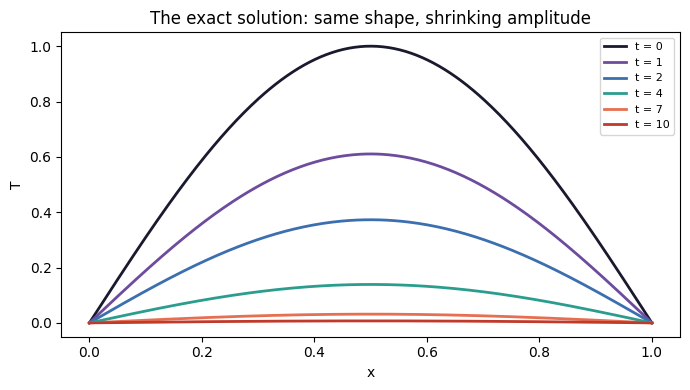

In [ ]:
xg = torch.linspace(0,1,300).reshape(-1,1)
plt.figure(figsize=(7,4))
for tv,c in zip([0,1,2,4,7,10], ["#1A1A2E","#6D4C9E","#3B6FB0","#2A9D8F","#E76F51","#02a718"]):
    plt.plot(xg.numpy(), exact(xg, torch.full_like(xg,float(tv))).numpy(), color=c, lw=2, label=f"t = {tv}")
plt.xlabel("x"); plt.ylabel("T"); plt.legend(fontsize=8)
plt.title("The exact solution: same shape, shrinking amplitude")
plt.tight_layout(); plt.show()

## 5 — Network, hard boundary conditions, and the residual

The network takes $(x,t)$ and returns a raw value; the **hard constraint** $T=x(1-x)N(x,t)$ makes both cold ends hold exactly, for every time, before training. That leaves only the PDE and the initial condition for the loss.

The residual is the heat equation itself. Note that $\partial T/\partial t$ is just another autograd call — time is a coordinate like any other.

In [4]:
class PINN(nn.Module):
    "Input (x,t) -> raw output N. Time bounds are set per window."
    def __init__(self, t0=0.0, t1=W_LEN, n_hidden=48, n_layers=4):
        super().__init__()
        layers = [nn.Linear(2,n_hidden), nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden,1)]
        self.net = nn.Sequential(*layers)
        self.register_buffer('lb', torch.tensor([0.0,t0]))
        self.register_buffer('ub', torch.tensor([1.0,t1]))
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self,x,t):
        z = 2.0*(torch.cat([x,t],dim=1)-self.lb)/(self.ub-self.lb) - 1.0
        return self.net(z)

def make_T(model):
    "Hard BC: T = 0 at x=0 and x=1, for every t."
    def T(x,t): return x*(1-x)*model(x,t)
    return T

def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True)[0]

def residual(T, x, t):
    "Heat equation residual: T_t - alpha*T_xx."
    u   = T(x,t)
    u_t = grad(u,t)                    # <- time derivative, just another autograd call
    u_xx = grad(grad(u,x),x)
    return u_t - ALPHA*u_xx

# verify the hard constraint before training
_m = PINN().to(device); _T = make_T(_m)
tt = torch.full((1,1), 1.0, device=device)
print(f"T(0,t) = {_T(torch.zeros(1,1,device=device),tt).item():.2e}   "
      f"T(1,t) = {_T(torch.ones(1,1,device=device),tt).item():.2e}   (exactly 0)")
print(f"parameters per window: {sum(p.numel() for p in _m.parameters())}")

T(0,t) = -0.00e+00   T(1,t) = 0.00e+00   (exactly 0)
parameters per window: 7249


## 6 — The causality problem, and time-windowing

Here is the conceptual heart of the tutorial.

A classical solver marches: it computes $t=0.1$, then uses that to compute $t=0.2$, and so on. Information flows forward, because that's how time works.

**A PINN does no such thing.** It scatters collocation points across the whole space–time domain and minimizes the residual everywhere *simultaneously*. It optimizes $t=9$ with exactly as much urgency as $t=0.1$, and nothing in the loss tells it that later times depend on earlier ones. It has **no sense of time's arrow**.

Over a short horizon this is survivable. Over a long one it degrades: the network fits the easy early times, smears the late ones, and the initial condition's influence washes out. You end up with a solution that satisfies the equation *on average* without ever being right.

### The fix: march in windows

**Time-windowing** restores causality by construction. Split $[0,10]$ into five windows of length 2 and solve them in order:

$$[0,2]\;\longrightarrow\;[2,4]\;\longrightarrow\;[4,6]\;\longrightarrow\;[6,8]\;\longrightarrow\;[8,10]$$

Each window's **initial condition is the previous window's solution** at the shared time. Three benefits:

- **Causality holds** — window $k{+}1$ cannot influence window $k$.
- **Every window is easy** — a short interval is a small, well-conditioned problem.
- **Warm starting compounds** — each window inherits the previous network's weights, so later windows start from a model that already understands the physics.

## 7 — Sampling and the loss

Points for one window: collocation scattered through $(x,t)$, and initial-condition points at $t=t_0$.

The loss has just two terms — the PDE residual, and the initial condition — because the boundaries are already hard-constrained. The IC is weighted heavily: it's the constraint that carries the handoff from one window to the next.

In [5]:
gen = torch.Generator().manual_seed(42)
def rb(a,b,n): return (a+(b-a)*torch.rand(n,1,generator=gen)).to(device)
W_IC = 100.0

def sample_window(t0, t1):
    "Collocation and initial-condition points for [t0, t1]."
    x_f = rb(0,1,N_f).requires_grad_(True)
    t_f = rb(t0,t1,N_f).requires_grad_(True)
    x_0 = rb(0,1,N_0)
    t_0 = torch.full_like(x_0, t0)
    return x_f, t_f, x_0, t_0

def make_losses(T, x_f, t_f, x_0, t_0, IC):
    def losses():
        loss_pde = (residual(T,x_f,t_f)**2).mean()
        loss_ic  = ((T(x_0,t_0) - IC)**2).mean()
        return loss_pde, loss_ic
    def total():
        lp,li = losses(); return lp + W_IC*li
    return losses, total

print(f"per window: {N_f} collocation points in (x,t), {N_0} initial-condition points")
print(f"initial condition weight: {W_IC}")

per window: 3000 collocation points in (x,t), 400 initial-condition points
initial condition weight: 100.0


## 8 — Marching through the horizon

For each window: build a network (warm-started from the previous), sample, take the initial condition from the previous window's solution, and train Adam → L-BFGS.

The first window's IC is the physical one, $\sin(\pi x)$. Every later window's IC is **whatever the previous window ended with** — that handoff is what makes this a march.

**Reference run** (real values, CPU, seeds as set here):
```
win 1  t=[0,2]   pde=4.70e-06  ic=1.17e-08  |  relL2 @ t=2  : 1.26e-03
win 2  t=[2,4]   pde=2.26e-06  ic=2.08e-09  |  relL2 @ t=4  : 2.77e-03
win 3  t=[4,6]   pde=1.38e-06  ic=1.17e-09  |  relL2 @ t=6  : 6.96e-03
win 4  t=[6,8]   pde=1.10e-06  ic=1.68e-09  |  relL2 @ t=8  : 1.21e-02
win 5  t=[8,10]  pde=9.45e-07  ic=2.12e-09  |  relL2 @ t=10 : 2.78e-02
```
The residual falls window on window (warm starting compounds) and the IC handoff stays at $10^{-9}$ — the windows are stitching together cleanly. The growing *relative* error is not a failure; Section 10 explains why.

In [6]:
def rel_error_at(T, t_val, n=200):
    "Relative L2 error against the exact solution at one time."
    x = torch.linspace(0,1,n,device=device).reshape(-1,1)
    t = torch.full_like(x, t_val)
    with torch.no_grad(): Tp = T(x,t)
    Te = exact(x,t)
    return (torch.linalg.norm(Tp-Te)/torch.linalg.norm(Te)).item()

window_models = []
history = {"win":[], "t1":[], "pde":[], "ic":[], "err":[]}
prev, prev_T = None, None

for k in range(N_WINDOWS):
    t0, t1 = k*W_LEN, (k+1)*W_LEN
    tic = time.time()

    model = PINN(t0,t1).to(device)
    if prev is not None:
        model.load_state_dict(prev.state_dict(), strict=False)     # warm start
        model.lb.copy_(torch.tensor([0.0,t0],device=device))
        model.ub.copy_(torch.tensor([1.0,t1],device=device))
    T = make_T(model)

    x_f,t_f,x_0,t_0 = sample_window(t0,t1)
    if prev is None:
        IC = torch.sin(PI*x_0)                                     # the physical IC
    else:
        with torch.no_grad(): IC = prev_T(x_0,t_0).clone()          # handoff

    losses, total = make_losses(T,x_f,t_f,x_0,t_0,IC)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for i in range(ADAM_ITERS):
        opt.zero_grad(); total().backward(); opt.step()
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS,
                            history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); L = total(); L.backward(); return L
    opt.step(closure)

    lp,li = losses(); err = rel_error_at(T,t1)
    history["win"].append(k+1); history["t1"].append(t1)
    history["pde"].append(lp.item()); history["ic"].append(li.item()); history["err"].append(err)
    print(f"win {k+1}  t=[{t0:.0f},{t1:.0f}]   pde={lp.item():.2e}  ic={li.item():.2e}  "
          f"|  relL2 @ t={t1:.0f} : {err:.2e}   ({time.time()-tic:.0f}s)")

    window_models.append((t0,t1,model,T))
    prev, prev_T = model, T

print(f"\nmarched to t = {T_END}")

win 1  t=[0,2]   pde=5.49e-06  ic=7.57e-09  |  relL2 @ t=2 : 1.26e-03   (16s)
win 2  t=[2,4]   pde=1.89e-06  ic=3.08e-10  |  relL2 @ t=4 : 2.28e-03   (9s)
win 3  t=[4,6]   pde=1.59e-06  ic=3.58e-09  |  relL2 @ t=6 : 4.89e-03   (9s)
win 4  t=[6,8]   pde=2.55e-06  ic=2.97e-09  |  relL2 @ t=8 : 1.07e-02   (7s)
win 5  t=[8,10]   pde=2.79e-06  ic=2.68e-09  |  relL2 @ t=10 : 2.75e-02   (8s)

marched to t = 10.0


## 9 — Results: watching the heat drain away

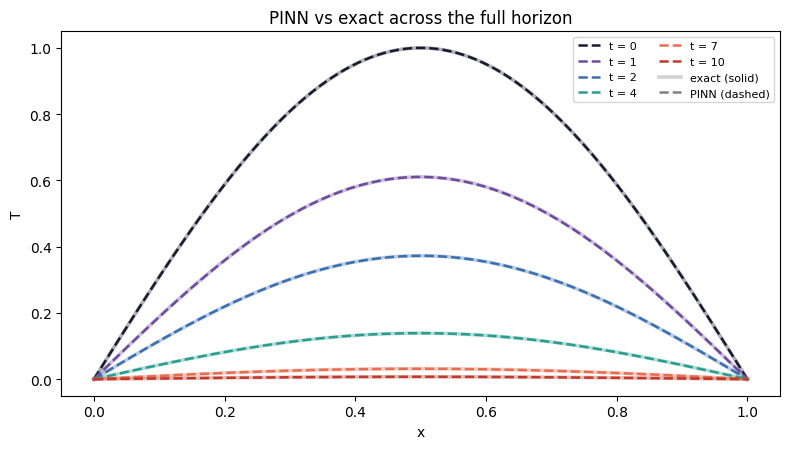

In [7]:
def T_at(t_val):
    "Pick the window that owns time t and return its solution function."
    for t0,t1,m,Tf in window_models:
        if t0 <= t_val <= t1: return Tf
    return window_models[-1][3]

x_plot = torch.linspace(0,1,300,device=device).reshape(-1,1)
plt.figure(figsize=(8,4.6))
for tv,c in zip([0,1,2,4,7,10], ["#1A1A2E","#6D4C9E","#3B6FB0","#2A9D8F","#E76F51","#c0392b"]):
    t = torch.full_like(x_plot, float(tv))
    with torch.no_grad(): Tp = T_at(tv)(x_plot,t)
    plt.plot(x_plot.cpu(), exact(x_plot,t).cpu(), color=c, lw=2.6, alpha=0.35)
    plt.plot(x_plot.cpu(), Tp.cpu(), '--', color=c, lw=1.8, label=f"t = {tv}")
plt.plot([],[],color='gray',lw=2.6,alpha=0.35,label='exact (solid)')
plt.plot([],[],'--',color='gray',lw=1.8,label='PINN (dashed)')
plt.xlabel("x"); plt.ylabel("T"); plt.legend(fontsize=8, ncol=2)
plt.title("PINN vs exact across the full horizon")
plt.tight_layout(); plt.show()

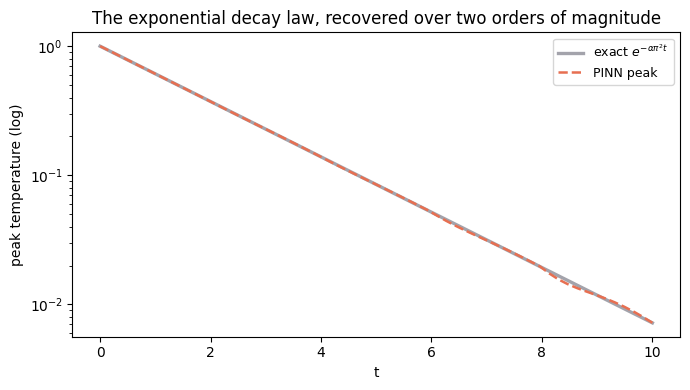

In [8]:
# the decay law: peak temperature vs exp(-alpha pi^2 t)
ts = np.linspace(0,T_END,60)
peaks_pinn, peaks_exact = [], []
for tv in ts:
    t = torch.full_like(x_plot, float(tv))
    with torch.no_grad(): Tp = T_at(float(tv))(x_plot,t)
    peaks_pinn.append(Tp.max().item()); peaks_exact.append(math.exp(-ALPHA*PI**2*tv))

plt.figure(figsize=(7,4))
plt.semilogy(ts, peaks_exact, color="#1A1A2E", lw=2.4, alpha=0.4, label='exact $e^{-\\alpha\\pi^2 t}$')
plt.semilogy(ts, peaks_pinn, '--', color="#E76F51", lw=1.8, label='PINN peak')
plt.xlabel("t"); plt.ylabel("peak temperature (log)"); plt.legend(fontsize=9)
plt.title("The exponential decay law, recovered over two orders of magnitude")
plt.tight_layout(); plt.show()

## 10 — Reading the error honestly

The relative error grew from $1.3\times10^{-3}$ to $2.8\times10^{-2}$ across the march. That looks like the solution degrading. It isn't — and understanding why is worth more than the number itself.

**The solution is vanishing.** By $t=10$ the exact peak temperature is $e^{-0.4935\times10}\approx0.0072$ — under 1% of where it started. Relative error divides by that shrinking quantity, so a *fixed* absolute error looks worse and worse as the signal disappears.

Check the absolute error instead and the picture is completely different — it stays flat at a few $\times10^{-4}$ the whole way.

**Reference values:**

| $t$ | exact peak | max abs error | rel $L_2$ |
|---|---|---|---|
| 8 | 0.01930 | 2.60e-04 | 1.15e-02 |
| 9 | 0.01178 | 4.03e-04 | 2.42e-02 |
| 10 | 0.00719 | 2.19e-04 | 2.77e-02 |

The lesson generalises: **for decaying solutions, always report absolute error alongside relative error.** A rising relative error on a vanishing field is usually arithmetic, not physics.

In [9]:
print(f"{'t':>5} {'exact peak':>12} {'PINN peak':>12} {'max abs err':>13} {'rel L2':>11}")
for tv in [0,2,4,6,8,10]:
    t = torch.full_like(x_plot, float(tv))
    with torch.no_grad(): Tp = T_at(float(tv))(x_plot,t)
    Te = exact(x_plot,t)
    print(f"{tv:5.1f} {Te.max().item():12.6f} {Tp.max().item():12.6f} "
          f"{(Tp-Te).abs().max().item():13.2e} {rel_error_at(T_at(float(tv)),float(tv)):11.2e}")

    t   exact peak    PINN peak   max abs err      rel L2
  0.0     0.999986     0.999970      2.83e-04    1.24e-04
  2.0     0.372703     0.372317      6.04e-04    1.26e-03
  4.0     0.138909     0.138843      3.57e-04    2.28e-03
  6.0     0.051773     0.051871      3.63e-04    4.89e-03
  8.0     0.019296     0.019319      2.81e-04    1.07e-02
 10.0     0.007192     0.007203      2.39e-04    2.75e-02


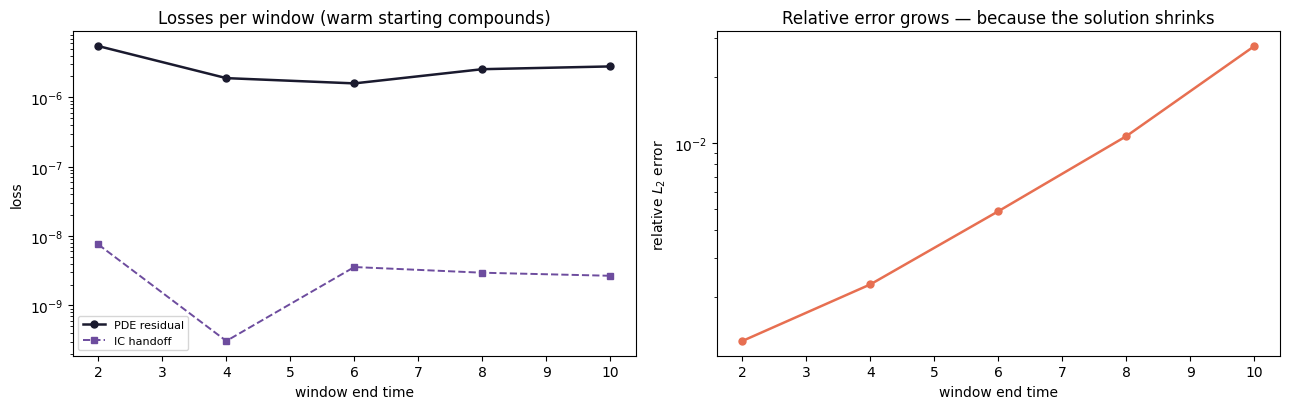

In [10]:
t1s=np.array(history["t1"])
fig,ax=plt.subplots(1,2,figsize=(13,4.2))
ax[0].semilogy(t1s,history["pde"],'o-',color="#1A1A2E",lw=1.8,ms=5,label='PDE residual')
ax[0].semilogy(t1s,history["ic"],'s--',color="#6D4C9E",lw=1.4,ms=4,label='IC handoff')
ax[0].set_xlabel('window end time'); ax[0].set_ylabel('loss')
ax[0].set_title('Losses per window (warm starting compounds)'); ax[0].legend(fontsize=8)
ax[1].semilogy(t1s,history["err"],'o-',color="#E76F51",lw=1.8,ms=5)
ax[1].set_xlabel('window end time'); ax[1].set_ylabel('relative $L_2$ error')
ax[1].set_title('Relative error grows — because the solution shrinks')
plt.tight_layout(); plt.show()

## 11 — Animated GIF

Sweep $t$ across the whole horizon, pull each frame from whichever window owns that time, and display it inline. The fixed axis makes the decay obvious.

saved heat_transient.gif


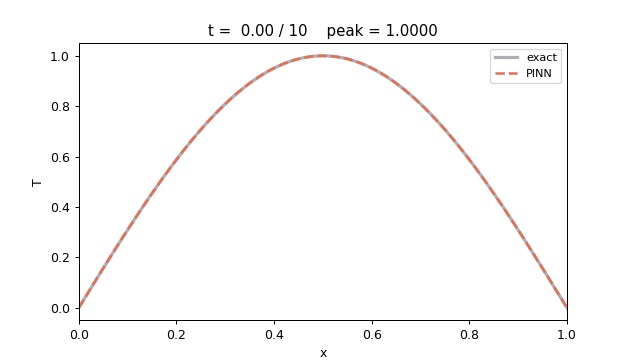

In [11]:
def make_gif(fname='heat_transient.gif', n_frames=100, fps=15, logscale=False):
    frames = np.linspace(0, T_END, n_frames)
    xs = x_plot.cpu().numpy().flatten()
    data = []
    for tv in frames:
        t = torch.full_like(x_plot, float(tv))
        with torch.no_grad(): Tp = T_at(float(tv))(x_plot,t)
        data.append((Tp.cpu().numpy().flatten(), exact(x_plot,t).cpu().numpy().flatten()))
    fig,ax = plt.subplots(figsize=(7,4))
    def draw(i):
        ax.clear()
        p,e = data[i]
        ax.plot(xs, e, color="#1A1A2E", lw=2.6, alpha=0.35, label='exact')
        ax.plot(xs, p, '--', color="#E76F51", lw=2, label='PINN')
        ax.set_xlim(0,1); ax.set_ylim(-0.05,1.05)
        ax.set_xlabel('x'); ax.set_ylabel('T'); ax.legend(loc='upper right', fontsize=9)
        ax.set_title(f"t = {frames[i]:5.2f} / {T_END:.0f}    peak = {p.max():.4f}")
        return []
    anim = FuncAnimation(fig, draw, frames=n_frames, blit=False)
    anim.save(fname, writer=PillowWriter(fps=fps), dpi=90)
    plt.close(fig)
    return fname

gif = make_gif()
print(f"saved {gif}")
display(Image(filename=gif))      # <-- plays inline

# If a GIF shows as a static frame in your viewer, this fallback usually works:
# from IPython.display import HTML; import base64
# b64 = base64.b64encode(open(gif,'rb').read()).decode()
# HTML(f'<img src="data:image/gif;base64,{b64}">')

## 12 — What You Have Built

Time cost almost nothing to add — one extra input, one extra autograd call, one extra loss term. What time cost was **structural**: a PINN doesn't know that the past comes before the future, and over a long horizon that ignorance shows.

| Change | Cost |
|---|---|
| time as a network input | one extra input neuron |
| $\partial T/\partial t$ in the residual | one autograd call |
| initial condition | one extra loss term |
| **ten time units of physics** | **five windows, each handing its end state to the next** |

**Why diffusion, and not flow?** An honest note, because it shaped this tutorial.

Time-dependent PINNs behave very differently depending on what's being transported. **Diffusion is forgiving**: it smooths, it decays, and the solution at late times is *simpler* than at early times — so a network converges to it readily, as you just saw at $10^{-6}$ residuals. **Convection is not.** In unsteady flow the interesting structures are sharp, they persist, and — worse — the equations usually admit a *steady* solution that the optimizer finds far more easily than the true unsteady one. A forward PINN on flow past a cylinder famously collapses onto the steady symmetric wake and never sheds a vortex, no matter how long you train.

So the honest summary is: **the machinery in this notebook is the right machinery for time — but it does not make every unsteady problem tractable.** Diffusion-dominated transients (heat, mass transfer, consolidation) work well. Convection-dominated ones need extra tools — data assimilation, causal weighting, or much shorter windows — and are a genuinely open research area.

**Diagnose it, always.** On any unsteady PINN, verify the solution actually changes with time before trusting a plot. Here that was easy (the peak decays). In harder problems, a converged loss on a silently-steady solution is the most dangerous failure mode there is.

---

### Failure modes to watch for

| Symptom | Cause | Fix |
|---|---|---|
| Late times inaccurate, early times fine | causality violation over a long horizon | **shorten the windows** — this is what windowing is for |
| **Relative error grows over time** | the solution is *decaying* — arithmetic, not physics | check **absolute** error too before concluding anything |
| Loss jumps at one window | the handoff degraded there | give that window more iterations, or halve `W_LEN` |
| IC term stays large | initial condition being ignored | raise `W_IC`; add more $t=t_0$ points |
| Solution drifts from the initial hump | first window's IC not enforced hard enough | check `IC = sin(pi x)` is applied in window 1 only |
| Solution is time-independent | $\partial T/\partial t$ missing from the residual | confirm `grad(u,t)` appears |

### Exercises

1. **Prove the causality problem.** Set `N_WINDOWS = 1` with `W_LEN = T_END` — one network over the whole horizon — and compare late-time error against the windowed run. The controlled demonstration of *why* windowing exists.
2. **Window-length sweep.** Try `W_LEN` of 1, 2, 5. Where's the balance between per-window difficulty and number of handoffs?
3. **Multi-mode initial condition.** Use $T(x,0)=\sin(\pi x)+\tfrac12\sin(3\pi x)$. The exact solution is now two modes decaying at *different* rates ($e^{-\alpha\pi^2t}$ and $e^{-9\alpha\pi^2t}$) — watch the high-frequency mode vanish first.
4. **A square pulse.** Start from a discontinuous initial condition. The exact solution is an infinite Fourier series; how well does the PINN handle the sharp corners as they smooth out?
5. **Inverse transient.** Combine with Tutorial 8: hide $\alpha$ and recover it from a few temperature readings taken at different times. Diffusivity from a cooling curve — a genuinely practical measurement.
6. **2D transient.** Extend to a cooling plate, $(x,y,t)\to T$. The machinery is unchanged; only the input dimension grows.
